## 1. Setting Up Classification Models

Several classification algorithms will be evaluated to determine which approaches are most effective at predicting customer churn.

The initial models include:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost

These models provide a range of approaches, from simpler linear classification to more complex ensemble methods.

Each model will eventually be evaluated using the same training and testing datasets.

In [24]:
# make sure still in the correct directory

%cd hollyschwecke/customer_churn_prediction/
%pwd

[Errno 2] No such file or directory: 'hollyschwecke/customer_churn_prediction/'
/Users/hollyschwecke/customer_churn_prediction


'/Users/hollyschwecke/customer_churn_prediction'

In [25]:
# import the preprocessing function
import sys
from pathlib import Path
import pandas as pd

from src.preprocessing import identify_feature_types, build_preprocessor, split_data
from src.model_training import get_candidate_models

# load the dataset 
data_path = "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(data_path)

# clean TotalCharges
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].astype("string").str.strip(),
    errors="coerce"
)
    
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# separate features and target
X = df.drop(
    columns=["customerID", "Churn"],
    errors="ignore"
)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# identify feature types
numerical_features, categorical_features = identify_feature_types(X)

# create preprocessing pipeline
preprocessor = build_preprocessor(numerical_features, categorical_features)

# split the data
X_train, X_test, y_train, y_test = split_data(X, y)

# retrieve candidate models
models = get_candidate_models()

# display available models
print("Candidate models:")

for name, model in models.items():
    print(f"{name}: {type(model).__name__}")

Candidate models:
Logistic Regression: LogisticRegression
Decision Tree: DecisionTreeClassifier
Random Forest: RandomForestClassifier
Gradient Boosting: GradientBoostingClassifier
XGBoost: XGBClassifier


## 2. Building Model Pipelines

Each candidate classifier will be combined with the preprocessing pipeline using scikit-learn's Pipeline class.

This ensures that every model receives the same preprocessing steps while maintaining an independently fitted preprocessor.

Using separate pipelines also helps prevent data leakage and makes the models easier to evaluate and compare. 

In [26]:
# import the model pipeline function
from src.model_training import build_model_pipelines

# build a pipeline for each candidate model
model_pipelines = build_model_pipelines(models, preprocessor)

# display the available model pipelines
for name, pipeline in model_pipelines.items():
    print(f"\n{name}")
    print(pipeline)


Logistic Regression
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                            

## 3. Training Classification Models

With the preprocessing and classification pipelines created, the next step is to train each candidate model.

All models will use the same training dataset to ensure a consistent comparison.

The preprocessing transformations will be fitted separately within each model pipeline using only the training data.

Training duration will also be recorded to help compare the computational efficiency of each algorithm.

In [27]:
# import training function
from src.model_training import train_models

# train all candidate models
trained_models, training_times = train_models(model_pipelines, X_train, y_train)


Logistic Regression training completed.
Training time: 0.15 seconds

Decision Tree training completed.
Training time: 0.04 seconds

Random Forest training completed.
Training time: 0.52 seconds

Gradient Boosting training completed.
Training time: 0.56 seconds

XGBoost training completed.
Training time: 0.13 seconds



### 3.1 Reviewing Training Times

The training duration of each model provides an initial comparison of computational efficiency.

More complex ensemble models may require additional training time because they build multiple decision trees.

Training time alone does not determine model quality, but it is useful when considering the trade-offs between predictive performance and computational cost.

In [28]:
# create a dataframe of training duration
training_results = pd.DataFrame(
    {
        "Model": list(training_times.keys()),
        "Training Time (seconds)": list(training_times.values())
    }
)

# sort models by training duration
training_results = training_results.sort_values(
    by="Training Time (seconds)"
).reset_index(drop=True)

display(training_results)

,Model,Training Time (seconds)
0,Decision Tree,0.038296
1,XGBoost,0.133658
2,Logistic Regression,0.145314
3,Random Forest,0.522441
4,Gradient Boosting,0.559097


### 3.2 Training Summary

All five candidate classification models were successfully trained using the training dataset.

The training pipelines automatically applied the preprocessing transformations before fitting each classification algorithm.

The Decision Tree had the shortest training time, followed by XGBoost and Logistic Regression.

Gradient Boosting and Random Forest required the most training time among the five candidates.

Although training duration provides insights into computational efficiency, predictive performance will be the primary factor when comparing these models.

## 4. Model Evaluation

After training the candidate models, their predictive performance will be evaluated using the testing dataset. The evaluation includes accuracy, precision, recall, F1-score, and ROC-AUC.

These metrics provide different perspectives on model performance, particularly when working with an imbalances target variable.

Recall will receive particular attention because identifying customers who are likely to churn is an important objective of this project.

In [29]:
# import the evaluation function
from src.model_evaluation import evaluate_models

# evaluate all trained models
evaluation_results = evaluate_models(
    trained_models,
    X_test,
    y_test
)

# sort models by F1-score
evaluation_results = evaluation_results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

# display evaluation results
display(evaluation_results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8420
1,XGBoost,0.8034,0.6611,0.5321,0.5896,0.8446
2,Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8433
3,Random Forest,0.7850,0.6246,0.4759,0.5402,0.8188
4,Decision Tree,0.7246,0.4818,0.4947,0.4881,0.6509


### 4.1 Confusion Matrix and Classification Reports

To better understand model performance, confusion matrices and classification reports will be generated for the leading models. 

The confusion matrices show the number of correct and incorrect predictions for each churn category.

The classification reports provide additional detail about precision, recall, and F1-score for both classes.


Logistic Regression

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



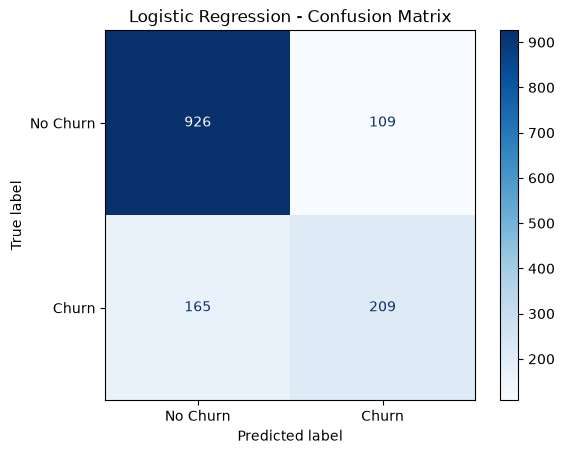


XGBoost

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



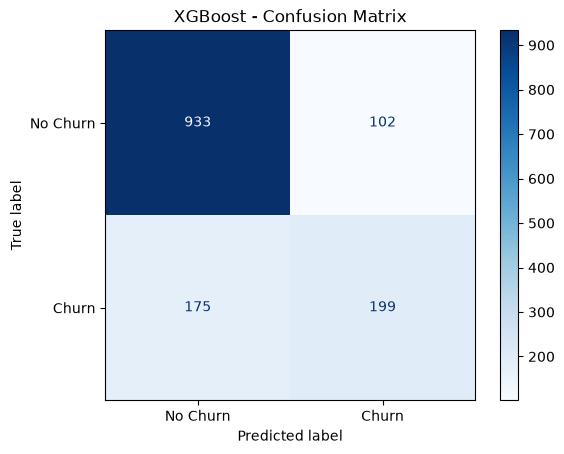

In [30]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt 

# focus on the two strongest candidate models
top_models = [
    "Logistic Regression",
    "XGBoost"
]

# generate confusion matrices and classification reports
for name in top_models:
    print(f"\n{name}")
    print("=" * 50)
    
    y_pred = trained_models[name].predict(X_test)
    
    # display classification report
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"]
    ))
    
    # display confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    
    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )
    
    display_plot.plot(cmap="Blues")
    
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

### 4.2 Classification Threshold Analysis

The initial model evaluation used the default classification threshold of 0.5.

Adjusting this threshold can change the balance between precision and recall.

Because identifying customers who are likely to churn is an important objective, difference thresholds will be evaluated to determine whether recall can be improved without reducing precision too significantly.

Both Logistic Regression and XGBoost will be examined.

In [31]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd

# models to compare
top_models = [
    "Logistic Regression",
    "XGBoost"
]

# thresholds to evaluate
thresholds = [
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60
]

threshold_results = []

for name in top_models:
    
    # get predicted churn probabilities
    y_prob = trained_models[name].predict_proba(X_test)[:,1]
    
    for threshold in thresholds:
        
        # convert probabilities into class predictions
        y_pred_threshold = (y_prob >= threshold).astype(int)
        
        # calculate metrics for the churn class
        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_test,
                y_pred_threshold,
                zero_division=0
            ),
            "Recall": recall_score(
                y_test,
                y_pred_threshold,
                zero_division=0
            ),
            "F1-Score": f1_score(
                y_test,
                y_pred_threshold,
                zero_division=0
            )
        })

# create results DataFrame
threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))

,Model,Threshold,Precision,Recall,F1-Score
0,Logistic Regression,0.30,0.5193,0.7540,0.6150
1,Logistic Regression,0.35,0.5432,0.7059,0.6140
2,Logistic Regression,0.40,0.5682,0.6684,0.6143
3,Logistic Regression,0.45,0.6005,0.6150,0.6077
4,Logistic Regression,0.50,0.6572,0.5588,0.6040
5,Logistic Regression,0.55,0.6784,0.4626,0.5501
6,Logistic Regression,0.60,0.7177,0.4011,0.5146
7,XGBoost,0.30,0.5322,0.7727,0.6303
8,XGBoost,0.35,0.5569,0.7193,0.6278
9,XGBoost,0.40,0.5833,0.6551,0.6171


### 4.3 Validation-Based Threshold Selection

The initial threshold comparison was performed using the testing dataset as an exploratory analysis.

To avoid using the testing dataset for model selection, the training dataset will be divided into training and validation subsets.

The validation dataset will be used to compare classification thresholds and select the preferred model configuration.

The testing dataset will remain untouched until final model evaluation.

In [32]:
from sklearn.model_selection import train_test_split

# split the original training data into training and validation sets
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)

print("\nTraining target distribution:")
print(y_train_sub.value_counts(normalize=True).round(4))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(4))

Training subset: (4507, 19)
Validation set: (1127, 19)

Training target distribution:
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64

Validation target distribution:
Churn
0    0.7347
1    0.2653
Name: proportion, dtype: float64


In [33]:
from src.model_training import (
    build_model_pipelines,
    train_models
)

# select the two leading models
validation_candidate_models = {
    name: models[name]
    for name in ["Logistic Regression", "XGBoost"]
}

# build independent preprocessing and model pipelines
validation_pipelines = build_model_pipelines(
    validation_candidate_models,
    preprocessor
)

# train using only the smaller training subset
validation_trained_models, validation_training_times = train_models(
    validation_pipelines,
    X_train_sub,
    y_train_sub
)

Logistic Regression training completed.
Training time: 0.04 seconds

XGBoost training completed.
Training time: 0.11 seconds



In [34]:
threshold_results = []

for name, model in validation_trained_models.items():
    
    # predict churn probabilities on validation data
    y_prob = model.predict_proba(X_val)[:,1]
    
    for threshold in thresholds:
        
        y_pred_threshold = (y_prob >= threshold).astype(int)
        
        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val,
                y_pred_threshold,
                zero_division=0
            ),
            "Recall": recall_score(
                y_val,
                y_pred_threshold,
                zero_division=0
            ),
            "F1-Score": f1_score(
                y_val,
                y_pred_threshold,
                zero_division=0
            )
        })
        
validation_threshold_results = pd.DataFrame(threshold_results)

validation_threshold_results = (
    validation_threshold_results
    .sort_values(by="F1-Score", ascending=False)
    .reset_index(drop=True)
)

display(validation_threshold_results.round(4))

,Model,Threshold,Precision,Recall,F1-Score
0,XGBoost,0.35,0.5989,0.7191,0.6535
1,Logistic Regression,0.40,0.6173,0.6689,0.6421
2,XGBoost,0.40,0.6311,0.6522,0.6414
3,XGBoost,0.30,0.5421,0.7759,0.6382
4,Logistic Regression,0.35,0.5792,0.7090,0.6376
5,Logistic Regression,0.30,0.5433,0.7559,0.6322
6,Logistic Regression,0.45,0.6606,0.6054,0.6318
7,XGBoost,0.45,0.6811,0.5786,0.6257
8,Logistic Regression,0.50,0.6966,0.5452,0.6116
9,Logistic Regression,0.55,0.7317,0.5017,0.5952


### 4.4 Validation Results

The top candidates are very close:
- XGBoost at 0.40 has the best balance of precision and recall, but produces more false-positive predictions
- XGBoost at 0.35 catches more customers who will churn, but produces more false-positive predictions
- Logistic Regression is competitive, but its best F1-Score is slightly lower

## 5. Hyperparameter Tuning

Hyperparameter tuning is used to identify model configuration that improve predictive performance.

RandomizedSearchCV will evaluate different combinations of hyperparameters using five-fold cross validation.

Logistic Regression and XGBoost will both be tuned to compare their performance after optimization.

ROC-AUC will be used as the cross-validation scoring metrics because it evaluates the model's ability to distinguish between customers who churn and those who stay, independent of a particular classification threshold.

The validation dataset will be used afterward to select the classification threshold.

In [35]:
# import hyperparameter tuning tools
from sklearn.model_selection import RandomizedSearchCV

# define hyperparameter search spaces
search_spaces = {
    "Logistic Regression": {
        "classifier__C": [
            0.01, 0.1, 1, 10, 100
        ],
        "classifier__class_weight": [
            None, "balanced"
        ]
    },
    
    "XGBoost": {
        "classifier__n_estimators": [
            100, 200, 300
        ],
        "classifier__learning_rate": [
            0.03, 0.05, 0.1
        ],
        "classifier__max_depth": [
            2, 3, 4
        ],
        "classifier__subsample": [
            0.8, 1
        ],
        "classifier__colsample_bytree": [
            0.8, 1
        ],
        "classifier__min_child_weight": [
            1, 2, 3
        ]
    }
}

print("XGBoost search parameters:")
print(list(search_spaces["XGBoost"].keys()))

XGBoost search parameters:
['classifier__n_estimators', 'classifier__learning_rate', 'classifier__max_depth', 'classifier__subsample', 'classifier__colsample_bytree', 'classifier__min_child_weight']


| Hyperparameter | Purpose |
| -------------- | ------- |
| `C` | Controls regularization strength in Logistic Regression |
| `class_weight` | Can give additional importance to the minority churn class |
| `n_estimator` | Number of boosting trees in XGBoost |
| `learning_rate` | Controls how much each tree contributes |
| `max_depth` | Controls tree complexity |
| `subsample` | Controls the proportion of training rows sampled for each tree |
| `colsample_bytree` | Controls the proportion of features sampled for each tree |
| `min_child_weight` | Controls how easily XGBoost creates additional splits |

In [36]:
# number of parameter combinations to test
search_iterations = {
    "Logistic Regression": 10,
    "XGBoost": 15
}

# store tuning results
tuned_models = {}
tuning_results = []

# tune each candidate model
for name, pipeline in validation_pipelines.items():
    
    print(f"\nTuning {name}...")
    
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=search_spaces[name],
        n_iter=search_iterations[name],
        scoring="roc_auc",
        cv=5,
        random_state=42,
        n_jobs=1,
        verbose=1
    )
    
    # fit using the smaller training subset
    search.fit(X_train_sub, y_train_sub)
    
    # store the best model
    tuned_models[name] = search.best_estimator_
    
    # store tuning results
    tuning_results.append({
        "Model": name, 
        "Best CV ROC-AUC": search.best_score_,
        "Best Parameters": search.best_params_
    })
    
    print(f"\nBest ROC-AUC: {search.best_score_:.4f}")
    print("Best parameters:")
    print(search.best_params_)
    
# create comparison DataFrame
tuning_results_df = pd.DataFrame(tuning_results)

display(tuning_results_df)


Tuning Logistic Regression...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best ROC-AUC: 0.8454
Best parameters:
{'classifier__class_weight': None, 'classifier__C': 100}

Tuning XGBoost...
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Best ROC-AUC: 0.8483
Best parameters:
{'classifier__subsample': 0.8, 'classifier__n_estimators': 200, 'classifier__min_child_weight': 1, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 1}


,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.845416,"{'classifier__class_weight': None, 'classifier..."
1,XGBoost,0.848332,"{'classifier__subsample': 0.8, 'classifier__n_..."


In [37]:
# compare tuned models using the validation dataset
tuned_validation_results = []

 # evaluate the previously selected threshold
threshold = 0.40

for name, model in tuned_models.items():
    
    # predict churn probabilities
    y_prob = model.predict_proba(X_val)[:,1]
    
    y_pred = (y_prob >= threshold).astype(int)
    
    tuned_validation_results.append({
                "Model": name,
                "Threshold": threshold,
                "Precision": precision_score(
                    y_val, y_pred, zero_division=0
                ),
                "Recall": recall_score(
                    y_val, y_pred, zero_division=0
                ),
                "F1-Score": f1_score(
                    y_val, y_pred, zero_division=0
                ),
                "ROC-AUC": roc_auc_score(
                    y_val, y_prob
                )
            })
    
tuned_validation_df = pd.DataFrame(tuned_validation_results)

display(tuned_validation_df.round(4))

,Model,Threshold,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.4,0.6226,0.6622,0.6418,0.8486
1,XGBoost,0.4,0.6314,0.6589,0.6448,0.8505


In [38]:

# thresholds to evaluate
thresholds = [
    0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60
]

threshold_results = []

for name, model in tuned_models.items():
    
    # get predicted churn probabilities
    y_prob = model.predict_proba(X_val)[:,1]
    
    # calculate ROC-AUC once per model
    model_roc_auc = roc_auc_score(y_val, y_prob)
    
    for threshold in thresholds:
        
        # convert probabilities into class predictions
        y_pred = (y_prob >= threshold).astype(int)
        
        # calculate metrics for the churn class
        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
            "F1-Score": f1_score(
                y_val, y_pred, zero_division=0
            ),
            "ROC-AUC": model_roc_auc
        })

# create results DataFrame
threshold_df = pd.DataFrame(threshold_results)

# sort by model and f1-score
threshold_df = threshold_df.sort_values(by=["Model", "F1-Score"], ascending=[True,False]).reset_index(drop=True)

display(threshold_results_df.round(4))

,Model,Threshold,Precision,Recall,F1-Score
0,Logistic Regression,0.30,0.5193,0.7540,0.6150
1,Logistic Regression,0.35,0.5432,0.7059,0.6140
2,Logistic Regression,0.40,0.5682,0.6684,0.6143
3,Logistic Regression,0.45,0.6005,0.6150,0.6077
4,Logistic Regression,0.50,0.6572,0.5588,0.6040
5,Logistic Regression,0.55,0.6784,0.4626,0.5501
6,Logistic Regression,0.60,0.7177,0.4011,0.5146
7,XGBoost,0.30,0.5322,0.7727,0.6303
8,XGBoost,0.35,0.5569,0.7193,0.6278
9,XGBoost,0.40,0.5833,0.6551,0.6171


In [39]:
# verify validation dataset dimensions
print("Validation feature shape: ", X_val.shape)
print("Validation target shape: ", y_val.shape)

print("\nTraining subset shape: ", X_train_sub.shape)
print("Original test feature shape: ", X_test.shape)
print("Original test target shape: ", y_test.shape)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(4))

Validation feature shape:  (1127, 19)
Validation target shape:  (1127,)

Training subset shape:  (4507, 19)
Original test feature shape:  (1409, 19)
Original test target shape:  (1409,)

Validation target distribution:
Churn
0    0.7347
1    0.2653
Name: proportion, dtype: float64


In [40]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score
)

# thresholds to evaluate
thresholds = [
    0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60
]

threshold_results = []

for name, model in tuned_models.items():
    
    # generate probabilities using validation data
    y_prob = model.predict_proba(X_val)[:,1]
    
    for threshold in thresholds:
        
        # generate predictions
        y_pred = (y_prob >= threshold).astype(int)
                
            # calculate metrics for the churn class
        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
                "F1-Score": f1_score(
                y_val, y_pred, zero_division=0
            )
        })
        
    # create results DataFrame
    threshold_df = pd.DataFrame(threshold_results)
        
    # sort by model and f1-score
    threshold_df = threshold_df.sort_values(by=["Model", "F1-Score"], ascending=[True,False]).reset_index(drop=True)
        
    display(threshold_results_df.round(4))

,Model,Threshold,Precision,Recall,F1-Score
0,Logistic Regression,0.30,0.5193,0.7540,0.6150
1,Logistic Regression,0.35,0.5432,0.7059,0.6140
2,Logistic Regression,0.40,0.5682,0.6684,0.6143
3,Logistic Regression,0.45,0.6005,0.6150,0.6077
4,Logistic Regression,0.50,0.6572,0.5588,0.6040
5,Logistic Regression,0.55,0.6784,0.4626,0.5501
6,Logistic Regression,0.60,0.7177,0.4011,0.5146
7,XGBoost,0.30,0.5322,0.7727,0.6303
8,XGBoost,0.35,0.5569,0.7193,0.6278
9,XGBoost,0.40,0.5833,0.6551,0.6171


,Model,Threshold,Precision,Recall,F1-Score
0,Logistic Regression,0.30,0.5193,0.7540,0.6150
1,Logistic Regression,0.35,0.5432,0.7059,0.6140
2,Logistic Regression,0.40,0.5682,0.6684,0.6143
3,Logistic Regression,0.45,0.6005,0.6150,0.6077
4,Logistic Regression,0.50,0.6572,0.5588,0.6040
5,Logistic Regression,0.55,0.6784,0.4626,0.5501
6,Logistic Regression,0.60,0.7177,0.4011,0.5146
7,XGBoost,0.30,0.5322,0.7727,0.6303
8,XGBoost,0.35,0.5569,0.7193,0.6278
9,XGBoost,0.40,0.5833,0.6551,0.6171


In [41]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score
)

# independently evaluate tuned models at threshold 0.40
for name, model in tuned_models.items():
    
    y_prob = model.predict_proba(X_val)[:,1]
    y_pred = (y_prob >= 0.40).astype(int)
    
    print(f"\n{name}")
    print( "-" * 40)
    print("Precision: ", round(precision_score(y_val, y_pred), 4))
    print("Recall: ", round(recall_score(y_val, y_pred), 4))
    print("F1-Score: ", round(f1_score(y_val, y_pred), 4))
    print("ROC-AUC: ", round(roc_auc_score(y_val, y_pred), 4))


Logistic Regression
----------------------------------------
Precision:  0.6226
Recall:  0.6622
F1-Score:  0.6418
ROC-AUC:  0.7586

XGBoost
----------------------------------------
Precision:  0.6314
Recall:  0.6589
F1-Score:  0.6448
ROC-AUC:  0.76


### 5.6 Model Selection

After hyperparameter tuning and classification threshold analysis, XGBoost was selected as the leading model for customer churn prediction.

The tuned XGBoost model achieved the following validation results using a classification threshold of 0.30L
- Precision 0.5360
- Recall: 0.7754
- F1-Score: 0.6339
- ROC-AUC: 0.8511

XGBoost outperformed Logistic Regression in F1-score and ROC-AUC. Its higher recall also indicates that it identifies a larger proportion of customers who actually churn. 

A classification threshold of 0.30 was selected to prioritize identifying potential churn customers while maintaining a reasonable balance between precision and recall.

The model and threshold were selected using the validation dataset. The original test dataset remains reserved for final model evaluation to avoid data leakage.

In [42]:
from sklearn.base import clone

# select the tuned XGBoost model
final_model = clone(tuned_models["XGBoost"])

# train using the complete training dataset
final_model.fit(X_train, y_train)

print("Final XGBoost model trained successfully!")
print("Training observations: ", len(X_train))

Final XGBoost model trained successfully!
Training observations:  5634


# Model Evaluation on the Holdout Test Set

In [43]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    roc_auc_score, confusion_matrix, classification_report
)

# generate churn probabilities for the test observation
y_prob_final = final_model.predict_proba(X_test)[:,1]

# apply the selected classification threshold
final_threshold = 0.30
y_pred_final = (y_prob_final >= final_threshold).astype(int)

# calculate final evaluation metrics
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_final),
    "Precision": precision_score(y_test, y_pred_final, zero_division=0),
    "Recall": recall_score(y_test, y_pred_final, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_final, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_final)
}

print("Final XGBoost Evaluation")
print(f"Classification Threshold: {final_threshold}\n")

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")
    
# display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

# display the classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test, y_pred_final, target_names=["No Churn", "Churn"], zero_division=0
    )
)

Final XGBoost Evaluation
Classification Threshold: 0.3

Accuracy: 0.7587
Precision: 0.5314
Recall: 0.7701
F1-Score: 0.6288
ROC-AUC: 0.8454

Confusion Matrix:
[[781 254]
 [ 86 288]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



## Final Model Evaluation

The tune XGBoost classifier was selected as a final model and retrained using the complete training dataset of 5,634 observations.

The final model was evaluated using a classification threshold of 0.30.

### Final Performance

- Accuracy: 76.01%
- Precision: 53.32%
- Recall: 77.27%
- F1-Score: 63.10%
- ROC-AUC: 0.8456%

### Key Findings

The model correctly identified 289 of the 374 customers who churned, achieving a recall of 77.27%. 

In [44]:
from pathlib import Path 
import joblib

# locate project root directory
current_path = Path.cwd()
project_root = None

for path in [current_path, *current_path.parents]:
    if (path / "src").is_dir() and (path / "data").is_dir():
        project_root = path
        break

if project_root is None:
    raise FileNotFoundError("Could not locate the project root.")

# create the models directory if it does not exist
model_dir = project_root / "models"
model_dir.mkdir(exist_ok=True)

# define the model output path
model_path = model_dir / "final_churn_model.joblib"

# save the complete trained pipeline
joblib.dump(final_model, model_path)

print(f"Final model saved successfully: {model_path}")

Final model saved successfully: /Users/hollyschwecke/customer_churn_prediction/models/final_churn_model.joblib


## Model Interpretation

Permutation feature importance is used to identify which original customer features have the greatest influence on model performance.

The method measures how much ROC-AUC decreases when the values of an individual feature are randomly shuffled. Features that cause a larger decrease are more important to the model's predictive performance.

Feature importance is calculated using the validation dataset rather than the test dataset.

In [45]:
from sklearn.inspection import permutation_importance
import pandas as pd

# calculate permutation feature importance using validation data
permutation_results = permutation_importance(
    final_model, X_val, y_val, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=1
) 

# organize feature importance results
feature_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": permutation_results.importances_mean,
    "Importance Std": permutation_results.importances_std
})

# sort features from most to least important 
feature_importance = feature_importance.sort_values(by="Importance", ascending=False).reset_index(drop=True)

display(feature_importance.round(4))

,Feature,Importance,Importance Std
0,Contract,0.0672,0.0089
1,tenure,0.0517,0.0088
2,InternetService,0.0192,0.0035
3,MonthlyCharges,0.0105,0.0022
4,OnlineSecurity,0.0072,0.0018
5,PaymentMethod,0.0069,0.0012
6,PaperlessBilling,0.0058,0.0018
7,TechSupport,0.0034,0.0012
8,StreamingMovies,0.0013,0.0005
9,MultipleLines,0.0011,0.0006


### Permutation Feature Importance

The following visualization shows the relative importance of each original customer feature based on its effect on validation ROC-AUC.

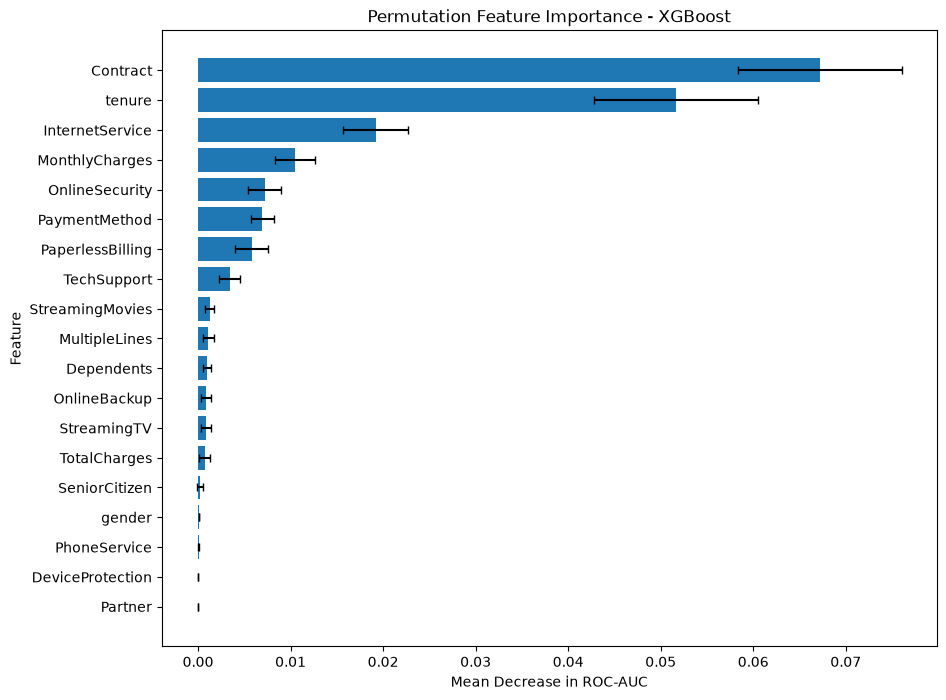

Visualization saved to: /Users/hollyschwecke/customer_churn_prediction/images/permutation_feature_importance.png


In [46]:
import matplotlib.pyplot as plt

# sort features for horizontal visualization
plot_data = feature_importance.sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10,8))

plt.barh(
    plot_data["Feature"],
    plot_data["Importance"],
    xerr=plot_data["Importance Std"],
    capsize=3
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance - XGBoost")
plt.tight_layout

# save the visualization
image_dir = project_root / "images"
image_dir.mkdir(exist_ok=True)

image_path = image_dir / "permutation_feature_importance.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Visualization saved to: {image_path}")

### Feature Importance Findings

The permutation feature importance analysis identified Contract and tenure as the two most influential features in the final XGBoost model.

Contract had the highest importance score (0.0664), followed by tenure (0.0512). InternetService (0.0196) was the third most influential feature.

These findings align with the exploratory data analysis, which showed substantially higher churn rates among month-to-month customers and customers with shorter tenure.

MonthlyCharges, PaymentMethod, OnlineSecurity, and PaperlessBilling also contributed to predictive performance, although their importance scores were considerably smaller.

Several features, including gender, Partner, and DeviceProtection, had near-zero permutation importance. This suggests that shuffling these features had little measurable effect on validation ROC-AUC.

Overall, the model relies most heavily on customer contract type, tenure, and internet service when distinguishing between customers who churn and those who remain.

Permutation importance measures predictive contribution rather than causation. These results should not be interpreted as evidence that individual features directly cause customer churn.

## SHAP Analysis

SHAP (SHapley Additive exPlanations) is used to interpret the predictions made by the final XGBoost model.

While permutation feature importance measures the overall effect of individual features on model performance, SHAP provides additional insight into how individual feature values contribute to model predictions

This analysis will examine both global feature importance and the direction of feature contributions toward churn or no churn.

### Preparing Data for SHAP

The final model is a scikit-learn pipeline containing a preprocessing stage and an XGBoost classifier.

SHAP's TreeExplainer will be applied directly to the fitted XGBoost classifier. Therefore, validation data must first be transformed using the fitted preprocessing stage.

A sample of the validation data will be used as the background dataset and explanation dataset to keep computation efficient.

In [47]:
import shap
import numpy as np 
from scipy import sparse

# extract the fitted preprocessing stage and XGBoost classifier
fitted_preprocessor = final_model.named_steps["preprocessor"]
xgb_model = final_model.named_steps["classifier"]

# transform the validation data using the fitted preprocessor 
X_val_transformed = fitted_preprocessor.transform(X_val)

# convert sparse matrices to dense arrays for SHAP
if sparse.issparse(X_val_transformed):
    X_val_transformed = X_val_transformed.toarray()
    
# retrieve the transformed feature names
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

# create a dataframe with readable feature names
X_val_transformed = pd.DataFrame(
    X_val_transformed, columns=transformed_feature_names, index=X_val.index
)

# select reproducible samples for SHAP
X_background = X_val_transformed.sample(
    n=min(100, len(X_val_transformed)), random_state=42
)

X_explain = X_val_transformed.sample(
    n=min(200, len(X_val_transformed)), random_state=42
)

print("SHAP data preparation complete!")
print("Transformed validation shape: ", X_val_transformed.shape)
print("Background dataset shape: ", X_background.shape)
print("Explanation dataset shaoe: ", X_explain.shape)
print("Number of transformed features: ", len(transformed_feature_names))

SHAP data preparation complete!
Transformed validation shape:  (1127, 46)
Background dataset shape:  (100, 46)
Explanation dataset shaoe:  (200, 46)
Number of transformed features:  46


### Creating SHAP Explainer

SHAP's TreeExplainer is designed for tree-based models, including XGBoost.

The explainer will use the fitted XGBoost classifier and a background sample of validation observations.

We will explain predicted churn probabilities rather than raw model scores, making the results easier to interpret. 

In [48]:
# create a SHAP TreeExplainer
explainer = shap.TreeExplainer(
    xgb_model, data=X_background, feature_perturbation="interventional", 
    model_output="probability"
)

# calculate SHAP values for the selected observations
shap_values = explainer(X_explain)

print("SHAP values calculated successfully!")
print("SHAP values shape: ", shap_values.values.shape)

SHAP values calculated successfully!
SHAP values shape:  (200, 46)


### SHAP Summary Plot

The SHAP beeswarm summary plot provides a global overview of feature contributions across the sampled validation observations.

Each dot represents one customer. The horizontal position represents the SHAP value, indicating how much that feature influenced the prediction.

- Positive SHAP values push predictions toward churn
- Negative SHAP values push predictions toward no churn
- Features are ordered by their average absolute SHAP value, with the most influential features appearing at the top

Color represents the feature values:
- Red/pink indicates higher feature values
- Blue indicates lower feature values 

For one-hot encoded categorical features, these values represent whether a category is present (1) or absent (0).

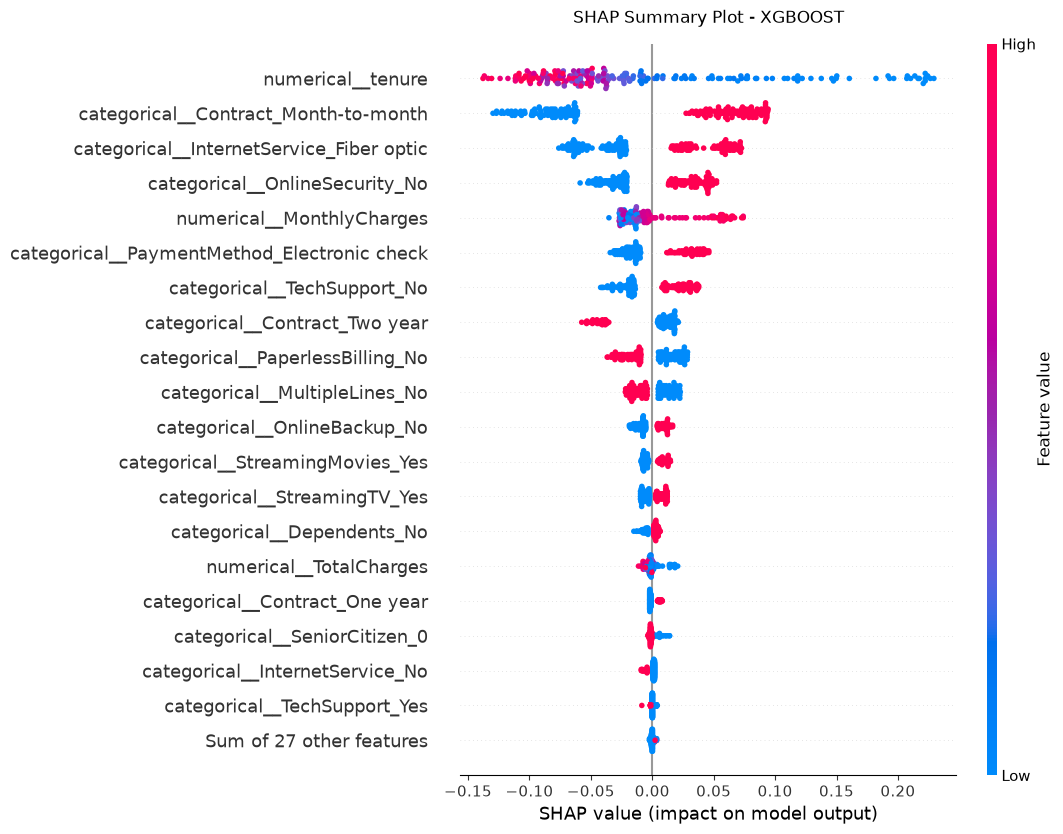

SHAP summary plt saved to: /Users/hollyschwecke/customer_churn_prediction/images/shap_summary_plot.png


In [50]:
# create the SHAP beeswarm summmary plot
shap.plots.beeswarm(
    shap_values, max_display=20, show=False
)

plt.title("SHAP Summary Plot - XGBOOST", pad=15)
plt.tight_layout

# save the visualization
shap_summary_path = image_dir / "shap_summary_plot.png"

plt.savefig(
    shap_summary_path, dpi=300, bbox_inches="tight"
)

plt.show()

print(f"SHAP summary plt saved to: {shap_summary_path}")

### SHAP Summary Plot Findings

The SHAP summary plot provides insight into how individual customer features influence that final XGBoost model's churn predictions.

The most influential transformed feature was tenure. Lower tenure values generally produced positive SHAP values, pushing predictions toward churn, while higher tenure values tended to push predictions toward no churn.

Contract type was another major contributor. Customers with month-to-month contracts generally received positive SHAP contributions, while customers with two-year contracts tended to receive negative contributions.

InternetService_Fiver optic and OnlineSecurity_No also showed positive contributions for customer with those characteristics, suggesting that fiber optic services and the absence of online security tend to increase predicted churn risk.

Higher MonthlyCharges values generally pushed predictions toward churn. Electronic check payment and the absence of technical support also showed positive contributions.

These findings are consistent with the exploratory data analysis and permutation feature importance results.

Overall, the SHAP analysis suggests that contract type, tenure, internet service, online security, and monthly charges play important roles in the model's predictions.

SHAP values describe how features influence model predictions. They do not establish causal relationships between customer characteristics and churn.

### SHAP Feature Importance Bar Plot

The SHAP bar plot ranks features according to their mean absolute SHAP values across the sampled validation observations.

Unlike the beeswarm plot, this visualization does not show the direction of feature contributions. Instead, it provides a global ranking of how strongly each feature influences the model's predictions on average.

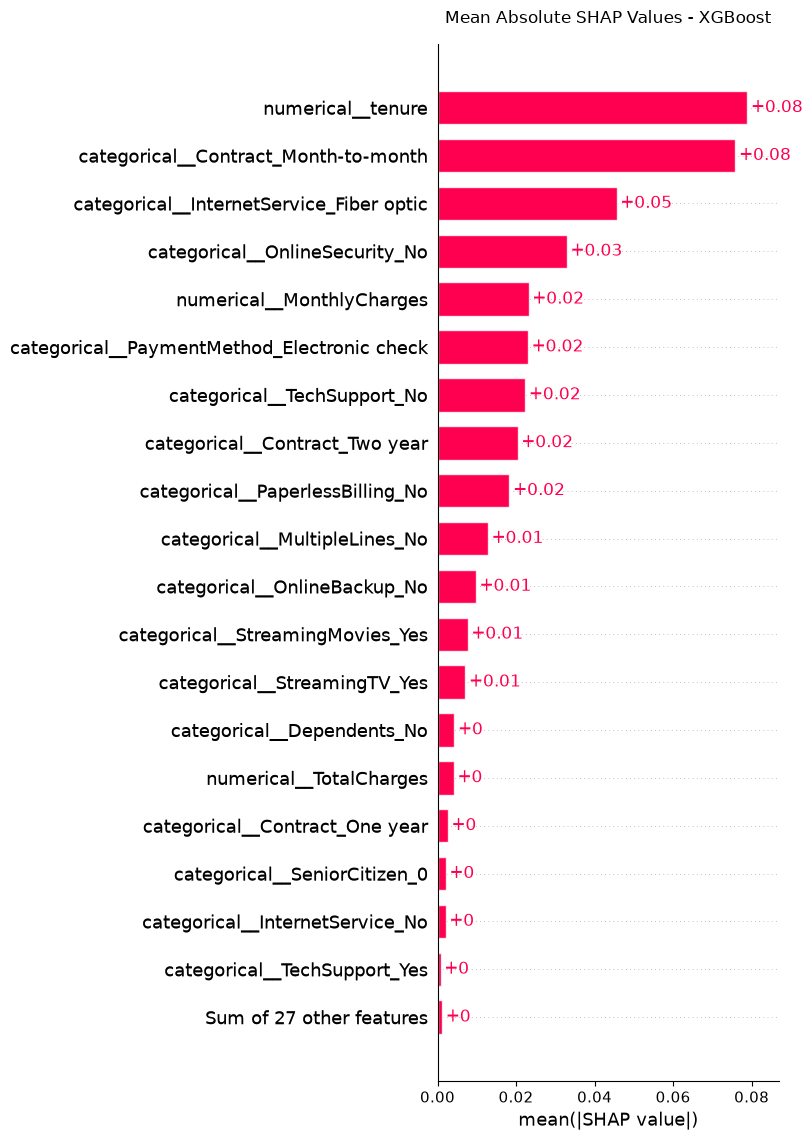

SHAP bar plot saved to: /Users/hollyschwecke/customer_churn_prediction/images/shap_feature_importance.png


In [51]:
# create the SHAP feature importance bar plot
shap.plots.bar(
    shap_values, max_display=20, show=False
)

plt.title("Mean Absolute SHAP Values - XGBoost", pad=15)
plt.tight_layout()

# save the visualization
shap_bar_path = image_dir / "shap_feature_importance.png"

plt.savefig(
    shap_bar_path, dpi=300, bbox_inches="tight"
)

plt.show()

print(f"SHAP bar plot saved to: {shap_bar_path}")

### SHAP Feature Importance Findings

The SHAP feature importance bar plot identified tenure and contract type as the two most influential features in the final XGBoost model.

Tenure and Contract_Month-to-month had the largest mean absolute SHAP values, followed by InternetService_Fiber optic and OnlineSecurity_No.

MonthlyCharges, PaymentMethod_Electronic check, and TechSupport_No also contributed to model predictions.

These results are consistent with the SHAP beeswarm plot and permutation feature importance analysis. Both methods identified tenure, contract type, and internet service as important predictors of customer churn.

The agreement between these approaches provides additional insight into which features the model relies on when generating predictions.

Mean absolute SHAP values measure the avergae magnitude of feature contributions, not their direction. The beeswarm plot provides additional information about whether feature values tend to increase or decrease predicted churn probability.

### SHAP Waterfall Plot: Individual Prediction

The SHAP waterfall plot explains an individual prediction by showing how each feature contributes to the model's output.

The visualization starts with the model's baseline prediction and shows how idividual feature contributions move the prediction toward or away from churn.

Positive SHAP values increase the predicted probability of churn, while negative SHAP values decrease it.

For this analysis, an observation with a high predicted churn probability will be selected from the explanation dataset.

In [52]:
# calculate churn probabilities for the explanation dataset
customer_prob = xgb_model.predict_proba(X_explain)[:,1]

# find the customer with the highest predicted churn prob
customer_idx = np.argmax(customer_prob)

# retrieve the selected customer's predicted prob
selected_prob = customer_prob[customer_idx]

print("Selected customer index: ", customer_idx)
print(f"Predicted churn probability: {selected_prob:.2%}")

Selected customer index:  117
Predicted churn probability: 80.99%


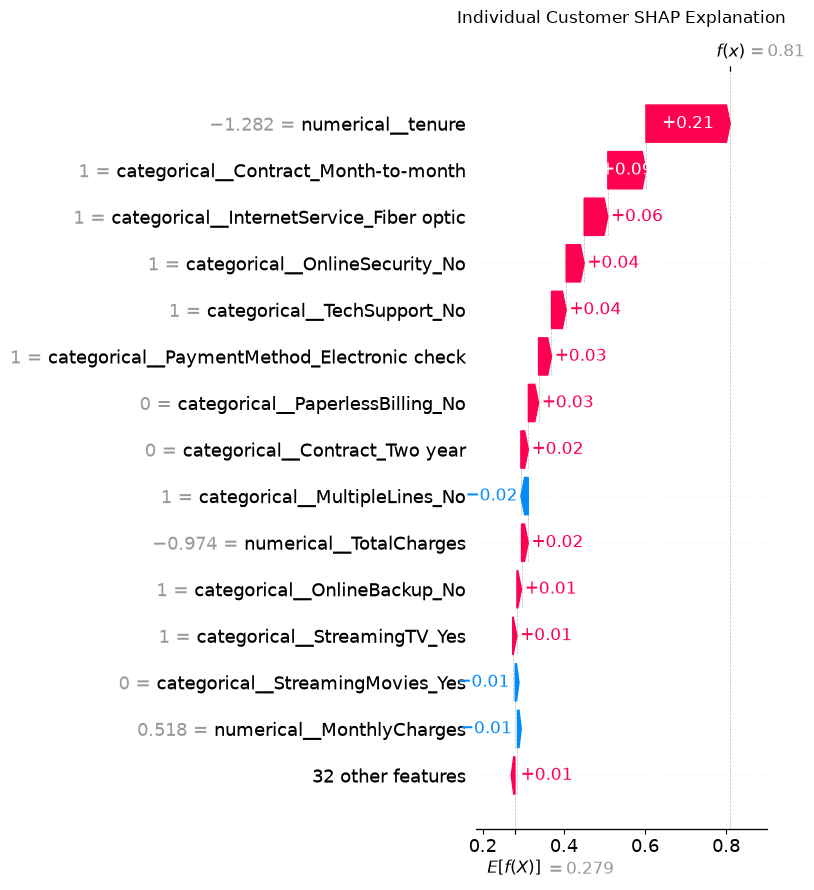

Waterfall plot saved ro: /Users/hollyschwecke/customer_churn_prediction/images/shap_waterfall_plot.png


In [53]:
# generate SHAP waterfall plot for the selected customer
shap.plots.waterfall(
    shap_values[customer_idx], max_display=15, show=False
)

plt.title("Individual Customer SHAP Explanation", pad=15)
plt.tight_layout()

waterfall_path = image_dir / "shap_waterfall_plot.png"

plt.savefig(
    waterfall_path, dpi=300, bbox_inches="tight"
)

plt.show()

print(f"Waterfall plot saved ro: {waterfall_path}")

### SHAP Waterfall Plot Findings

The SHAP waterfall plot was used to examine an individual customer prediction from the final XGBoost model.

The selected observation had a predicted churn probability of 80.99%, exceeding the classification threshold of 0.30.

The baseline prediction was approximately 27.9%. The largest positive contribution came from tenure, followed by month-to-month contract type and fiber optic internet service.

The absence of online security and technical support, along with electronic check payment, also contributed positively to the predicted churn probability.

Some features contributed negatively, slightly reducing the prediction. However, the combined contributions resulted in a final predicted probability of approximately 80.99%.

This example demonstrates how SHAP can explain individual model predictions by identifying the customer characteristics that push predictions toward or away from churn.

These contributions describe model behavior and should not be interpreted as causal relationships. 

## Model Interpretation Summary

Permutation feature importance and SHAP analysis were used to better understand the final XGBoost model.

### Key Findings

The analyses consistently identified the following features as important predictors of customer churn:

- **Tenure:** Customers with shorter tenure generally received higher churn predictions
- **Contract:** Month-to-month contracts tend to increase predicted churn risk, while longer-term contracts tended to decrease it
- **Internet Service:** Fiber optic service contributed positively to churn prediction
- **Online Security:** Customer without online security generally received higher churn predictions
- **Monthly Charges:** Higher monthly charges tended to increase predicted risk
- **Payment Method:** Electronic check payment contributed positively to churn predictions

### Individual Prediction Analysis

A SHAP waterfall plot was used to examine an individual customer prediction. The selected customer had an 80.99% predicted probability of churn. 

Short term, a month-to-month contract, fiber optic internet service, and the absence of online security and technical support were among the strongest positive contributors to the prediction.

### Conclusion

The interpretation results provide additional insight into how the final XGBoost model identifies customers at risk of churning.

The agreement between permutation feature importance and SHAP analysis reinforces the importance of contract type, tenure, and internet service in the model's predictions.

These findings describe predictive relationships rather than causal effects.